# 05 — Fundamentos de Probabilidade

**Objetivos de aprendizagem:** usar regras de eventos, condicionamento, independência e o teorema de Bayes introdutório

**Pré-requisitos:** Álgebra básica

**Origem:** Slides, aula 07, páginas 146–164; aprofundamento: Bayes ilustrativo. Conteúdos adicionais estão identificados como **Aprofundamento**.

**Convenção:** `datasets/` reúne dados de entrada; `outputs/` reúne resultados. Dados inventados para demonstrações são sempre identificados como *sintéticos*.

### Materiais complementares

- [Guia Técnico](./reference_materials/05_fundamentos_de_probabilidade.pdf)
- [Cheat Sheet](./cheat_sheets/cheat_sheet_fundamentos_de_probabilidade.pdf)


## Preparação do ambiente

Execute a célula abaixo. Os notebooks são independentes e não dependem de variáveis definidas em outros arquivos.

> **Resultados reproduzíveis:** gráficos PNG e tabelas CSV selecionados são gravados automaticamente em `outputs/` ao executar as células na ordem. Os arquivos em `datasets/` são preservados. Esta disciplina usa Matplotlib, não o renderer `iframe` do Plotly.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Execute o JupyterLab com o diretório desta disciplina como raiz.
BASE = Path.cwd()
DATASETS = BASE / "datasets"
OUTPUTS = BASE / "outputs"
DATASETS.mkdir(parents=True, exist_ok=True)
OUTPUTS.mkdir(parents=True, exist_ok=True)

def ler_dataset(nome):
    caminho = DATASETS / nome
    if not caminho.is_file():
        raise FileNotFoundError(f"Dataset não encontrado: {caminho}. Abra o JupyterLab na raiz da disciplina.")
    return pd.read_csv(caminho)

RNG = np.random.default_rng(42)

## 1. Experimentos e eventos

Um espaço amostral contém os resultados possíveis; eventos são subconjuntos. Para eventos equiprováveis, P(A)=casos favoráveis/casos possíveis. Não aplique essa razão quando resultados não forem equiprováveis.

In [2]:
omega=set(range(1,7));A={2,4,6};B={4,5,6}
print('P(A)',len(A)/len(omega),'P(B)',len(B)/len(omega))
print('P(A∩B)',len(A&B)/6,'P(A∪B)',len(A|B)/6)
assert len(A|B)==len(A)+len(B)-len(A&B)

P(A) 0.5 P(B) 0.5
P(A∩B) 0.3333333333333333 P(A∪B) 0.6666666666666666


## 2. Condicional e independência

P(A|B)=P(A∩B)/P(B) se P(B)>0. Independência exige P(A∩B)=P(A)P(B); eventos disjuntos com probabilidades positivas não são independentes.

In [3]:
pA=len(A)/6;pB=len(B)/6;p_inter=len(A&B)/6
print('P(A | B)=',p_inter/pB,'P(A)P(B)=',pA*pB)

P(A | B)= 0.6666666666666666 P(A)P(B)= 0.25


In [4]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'evento':['A','B','intersecao','uniao','A_dado_B'], 'probabilidade':[pA,pB,p_inter,len(A|B)/6,p_inter/pB]}).to_csv(OUTPUTS / '05_probabilidades_eventos.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


## 3. Simulação: frequências convergem

Frequência observada aproxima a probabilidade teórica sob repetição independente, mas não precisa convergir monotonicamente nem fornece certeza em uma única amostra.

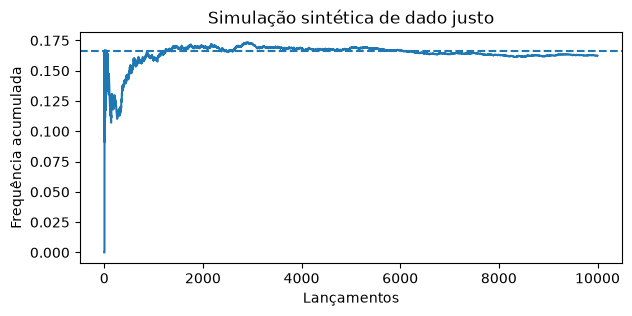

In [5]:
lanc=RNG.integers(1,7,10000)
fracao=np.cumsum(lanc==6)/np.arange(1,len(lanc)+1)
fig,ax=plt.subplots(figsize=(7,3));ax.plot(fracao);ax.axhline(1/6,ls='--');ax.set(xlabel='Lançamentos',ylabel='Frequência acumulada',title='Simulação sintética de dado justo');fig.savefig(OUTPUTS / '05_frequencia_acumulada_dado.png', dpi=160, bbox_inches='tight');plt.show()

## 4. Teorema de Bayes — primeiro contato (aprofundamento)

Se P(D) é prevalência e P(+|D) sensibilidade, P(D|+) depende também da taxa de falso positivo P(+|não D). Em testes raros, um positivo não garante alta probabilidade posterior.

In [6]:
prev=.01;sens=.95;espec=.90
ppv=sens*prev/(sens*prev+(1-espec)*(1-prev))
print('P(condição | positivo)=',round(ppv,4))

P(condição | positivo)= 0.0876


In [7]:
# Exportação reproduzível para outputs/ (dados e resultados didáticos)
pd.DataFrame({'prevalencia':[prev], 'sensibilidade':[sens], 'especificidade':[espec], 'valor_preditivo_positivo':[ppv]}).to_csv(OUTPUTS / '05_exemplo_bayes.csv',index=False,encoding='utf-8-sig')
print('Resultados exportados em:', OUTPUTS)

Resultados exportados em: /run/media/eduardo/Backup/Faculdades/PUC - CIENCIA DE DADOS/PUC/02_Disciplinas/03_statistics/outputs


### Exercício resolvido — Conferência da união de eventos

**Solução comentada:**

In [8]:
pa=3/6;pb=3/6;pab=2/6
resultado=pa+pb-pab
assert np.isclose(resultado,4/6)
print('P(A união B)',resultado)

P(A união B) 0.6666666666666667


**Interpretação:** A fórmula subtrai a interseção para não contar resultados comuns duas vezes.

## Erros comuns e limites

Não confunda P(A|B) com P(B|A). Inferência bayesiana completa, com distribuições a priori e posteriores, pertence ao Notebook 09.

## Consulta Rápida

`P(A∪B)=P(A)+P(B)−P(A∩B)`; `P(A|B)=P(A∩B)/P(B)`; `P(A|B)=P(B|A)P(A)/P(B)` (Bayes).

## Autoavaliação

Antes de seguir, explique com suas palavras: **qual é a pergunta estatística, qual método responde a ela, quais pressupostos devem ser verificados e o que não podemos concluir?**

## Aprofundamento v2 — Teorema de Bayes e taxa-base

A taxa-base de ocorrência é parte indispensável da interpretação de testes. `P(positivo | condição)` (sensibilidade) é distinta de `P(condição | positivo)` (valor preditivo positivo). Mesmo testes com alta sensibilidade podem produzir muitos falsos positivos quando a condição é rara.

In [9]:
def valor_preditivo_positivo(prevalencia, sensibilidade, especificidade):
    assert 0 <= prevalencia <= 1 and 0 <= sensibilidade <= 1 and 0 <= especificidade <= 1
    numerador = sensibilidade * prevalencia
    denominador = numerador + (1 - especificidade)*(1-prevalencia)
    return numerador / denominador if denominador > 0 else np.nan
prevalencias = np.array([.01, .05, .20])
resultados_bayes = pd.DataFrame({
    'prevalencia': prevalencias,
    'valor_preditivo_positivo': [valor_preditivo_positivo(p,.95,.90) for p in prevalencias]
})
display(resultados_bayes.round(3))
assert resultados_bayes['valor_preditivo_positivo'].is_monotonic_increasing

,prevalencia,valor_preditivo_positivo
0,0.01,0.088
1,0.05,0.333
2,0.20,0.704


### Exercício resolvido

**Pergunta:** a sensibilidade do teste aumentou. É sempre possível concluir que `P(condição | positivo)` aumentou?

**Solução:** não sem conhecer prevalência e especificidade. Essas três quantidades entram na fórmula de Bayes e alteram o valor preditivo positivo.